# Project Assignment 1

Time Series and Forecasting

In [1]:
## Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.dates as mdates

## Plot definitions
plt.style.use('ggplot')
pd.set_option('display.max_columns', 30)

In [2]:
## Load Data
project_dir = Path.cwd().parent
data_dir = project_dir / 'data'

olim_1989_2023 = (data_dir / 'olim-month-of-year-1989-2023.csv')
olim_2024      = (data_dir / "olim1_2024.xlsx")
olim_2025      = (data_dir / "olim1_2025.xlsx")

olim_1989_2023_raw = pd.read_csv(olim_1989_2023)
olim_2024_raw      = pd.read_excel(olim_2024)
olim_2025_raw      = pd.read_excel(olim_2025)

gpr = (data_dir / 'data_gpr_month.xls')
gpr_raw = pd.read_excel(gpr)



## 1. Description of the Selected Time Series and Their Expected Relationship

#### Main Series - New Olim by Month between 01.1989 - 12.2025 : 
A breakdown of the number of immigrants (Olim) arriving in Israel from January 1989 to December 2025, comprising 444 monthly observations. The series allows us to examine changes in immigration over time.

#### Exogenous Series - Israel's Geopolitical Risk Index (GPR)
The exogenous series is Israel's country-specific Geopolitical Risk Index (GPR), developed by Caldara and Iacoviello. The index is based on the monthly share of newspaper articles discussing geopolitical threats, tensions, and events that mention Israel or its major cities. Higher index values indicate greater reported geopolitical risk associated with Israel.


#### Expected Relationship : 
We hypothesize a negative relationship between geopolitical risk in Israel and the number of new immigrants arriving in the country. During periods of heightened security tensions or geopolitical instability, Israel may be perceived as a less attractive destination for immigration, potentially causing prospective immigrants to postpone their arrival. However, immigration decisions are complex and influenced by various factors. Therefore, changes in geopolitical risk may affect immigration with a lag of several months rather than immediately. Additionally, geopolitical events in immigrants' countries of origin may also influence immigration patterns.


## 2. Raw Data Sources

#### Main Series - New Olim by Month and Year - 
https://data.gov.il/he/datasets/ministry_of_immigrant_absorption/new-olim-by-month (1989-2023)

https://www.gov.il/he/pages/aliyah-data-2024

https://www.gov.il/he/pages/aliyah-data-2025

#### Exogenic Series - GPR specefic country :
https://www.matteoiacoviello.com/gpr_country.htm

In [3]:
olim_1989_2023_raw.head(n=20)

,year,month,olim
0,1989,1,1116
1,1989,2,1156
2,1989,3,1761
3,1989,4,1154
4,1989,5,1528
5,1989,6,1201
6,1989,7,1772
7,1989,8,2158
8,1989,9,2227
9,1989,10,2795


In [4]:
olim_2024_raw.head(n=20) # showing only 2024 as 2024 & 2025 are of the same structure

,לוח 1 : התפלגות עולים לפי תתי יבשות מוצא וחודש עליה ומגדר -מ 1/1/2024 עד 31/12/2024,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,מגדר,NaN,NaN,"סה""כ עולים",חודש עליה,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,ינואר,פברואר,מרץ,אפריל,מאי,יוני,יולי,אוגוסט,ספטמבר,אוקטובר,נובמבר,דצמבר
3,"סה""כ","סה""כ",NaN,32161,2425,2578,3314,2077,3436,3057,3324,3245,2838,1229,2627,2011
4,NaN,תת יבשת,מזרח אירופה,22833,1777,2075,2716,1619,2789,2402,2035,1455,1778,779,1998,1410
5,NaN,NaN,מערב אירופה,3562,203,183,197,188,185,252,590,686,409,194,276,199
6,NaN,NaN,צפון אמריקה,3723,206,182,162,168,225,261,495,934,479,166,204,241
7,NaN,NaN,מרכז דרום אמריקה,1017,133,57,100,53,175,63,114,84,103,20,72,43
8,NaN,NaN,ארצות ערב אפריקה,32,0,10,0,3,1,0,6,0,0,3,5,4
9,NaN,NaN,שאר אפריקה,402,43,33,88,19,25,33,30,34,19,22,22,34


In [5]:
gpr_raw.head(n=20)

,month,GPR,GPRT,GPRA,GPRH,GPRHT,GPRHA,SHARE_GPR,N10,SHARE_GPRH,N3H,GPRH_NOEW,GPR_NOEW,GPRH_AND,GPR_AND,...,GPRHC_PRT,GPRHC_RUS,GPRHC_SAU,GPRHC_SWE,GPRHC_THA,GPRHC_TUN,GPRHC_TUR,GPRHC_TWN,GPRHC_UKR,GPRHC_USA,GPRHC_VEN,GPRHC_VNM,GPRHC_ZAF,var_name,var_label
0,1900-01-01,NaN,NaN,NaN,87.927849,64.717491,110.453522,NaN,NaN,3.171932,7724,92.189819,NaN,116.949104,NaN,...,0.245987,0.258933,0.0,0.012947,0.077680,0.000000,0.038840,0.000000,0.0,2.718799,0.051787,0.012947,1.152253,month,Date (year/month)
1,1900-02-01,NaN,NaN,NaN,86.566490,71.936844,96.250488,NaN,NaN,3.122822,7173,91.032326,NaN,131.074982,NaN,...,0.139412,0.334588,0.0,0.000000,0.083647,0.000000,0.125471,0.000000,0.0,2.732469,0.027882,0.000000,1.143176,GPR,Recent GPR (Index: 1985:2019=100)
2,1900-03-01,NaN,NaN,NaN,72.140701,57.475853,84.499428,NaN,NaN,2.602422,7762,77.067757,NaN,112.938850,NaN,...,0.051533,0.386498,0.0,0.012883,0.115949,0.000000,0.180366,0.000000,0.0,2.151507,0.025767,0.000000,0.863180,GPRT,Recent GPR Threats (Index: 1985:2019=100)
3,1900-04-01,NaN,NaN,NaN,54.419449,37.326603,65.858208,NaN,NaN,1.963141,7488,61.985249,NaN,99.778038,NaN,...,0.080128,0.267094,0.0,0.000000,0.040064,0.000000,0.066774,0.000000,0.0,1.776175,0.000000,0.000000,0.641026,GPRA,Recent GPR Acts (Index: 1985:2019=100)
4,1900-05-01,NaN,NaN,NaN,64.405197,48.200008,74.373955,NaN,NaN,2.323370,7360,64.238335,NaN,105.352043,NaN,...,0.081522,0.176630,0.0,0.000000,0.163043,0.000000,0.081522,0.000000,0.0,1.970109,0.013587,0.000000,0.788043,GPRH,Historical GPR (Index: 1900:2019=100)
5,1900-06-01,NaN,NaN,NaN,83.610252,70.006577,93.977692,NaN,NaN,3.016178,7294,77.467339,NaN,124.273941,NaN,...,0.068549,0.945983,0.0,0.013710,0.082259,0.013710,0.109679,0.027420,0.0,2.728270,0.027420,0.041130,0.671785,GPRHT,Historical GPR Threats (Index: 1900:2019=100)
6,1900-07-01,NaN,NaN,NaN,108.571121,87.062378,125.709084,NaN,NaN,3.916622,7532,95.879486,NaN,134.726196,NaN,...,0.039830,1.035581,0.0,0.013277,0.252257,0.000000,0.146044,0.039830,0.0,3.544875,0.026553,0.026553,0.292087,GPRHA,Historical GPR Acts (Index: 1900:2019=100)
7,1900-08-01,NaN,NaN,NaN,108.502815,63.841644,149.760986,NaN,NaN,3.914158,7409,95.914795,NaN,126.370201,NaN,...,0.026994,1.106762,0.0,0.040491,0.242948,0.013497,0.080983,0.040491,0.0,3.549737,0.026994,0.013497,0.242948,SHARE_GPR,Percent of Recent GPR Articles
8,1900-09-01,NaN,NaN,NaN,62.813301,54.698414,67.581779,NaN,NaN,2.265943,7370,65.520256,NaN,108.190735,NaN,...,0.094980,0.786974,0.0,0.000000,0.135685,0.000000,0.040706,0.013569,0.0,2.008141,0.013569,0.000000,0.176391,N10,"Number of articles (10 recent newspapers, 1985-)"
9,1900-10-01,NaN,NaN,NaN,43.366932,31.717627,51.432850,NaN,NaN,1.564430,7287,46.683296,NaN,88.744675,NaN,...,0.013723,0.178400,0.0,0.013723,0.068615,0.000000,0.027446,0.000000,0.0,1.262522,0.000000,0.000000,0.205846,SHARE_GPRH,Percent of Historical GPR Articles


## 3. Description of the Processing Applied to the Time Series

In [6]:
### olim Processing
start_year = 1989

olim_until_2023_df = olim_1989_2023_raw[ olim_1989_2023_raw["year"] >= start_year ]["olim"] \
                        .reset_index(drop=True) # selecting start_year-2023 range

olim_2024_df = olim_2024_raw.iloc[3, 4:].reset_index(drop=True)

olim_2025_df = olim_2025_raw.iloc[3, 4:].reset_index(drop=True)

df_lst = [olim_until_2023_df, olim_2024_df, olim_2025_df]

for df in df_lst :
    assert df.isna().any(axis=0) == False, f"NaN values in dataframe {df}" # nan values check
    assert df.eq(' ').sum() == 0,  f"missing values in dataframe {df}"     # blank values check

olim = pd.concat(df_lst, axis=0) \
                    .reset_index(drop=True)

olim

0      1116
1      1156
2      1761
3      1154
4      1528
       ... 
439    2918
440    1989
441    1711
442    1722
443    1683
Length: 444, dtype: object

In [7]:
### gpr_ISR Processing
end_year = 2026
end_month = 1
country="ISR"

gpr_ISR = gpr_raw[ (gpr_raw['month'] >= f"{start_year}-01-01") & (gpr_raw['month'] < f"{end_year}-{end_month}-01") ] \
    .filter(like = f'GPRC_{country}') \
    .reset_index(drop = True) 
       

assert gpr_ISR.isna().any(axis=0).values == False # nan values check
assert gpr_ISR.eq(' ').sum().values == 0          # blank values check


gpr_ISR



,GPRC_ISR
0,0.587705
1,0.459546
2,0.431191
3,0.371386
4,0.411625
...,...
439,1.521739
440,1.384716
441,1.488616
442,0.584575


For the analysis, the common time period of January 1989 to December 2025 was selected for both time series, resulting in 444 monthly observations per series.

Main Series - Monthly Number of New Immigrants to Israel (Olim): Data from additional sources were combined with the original dataset to complete the years 2024-2025, while maintaining a monthly frequency.

Exogenous Series - Israel's Geopolitical Risk Index (GPR): The data were obtained from the Caldara and Iacoviello database, which contains geopolitical risk indices for different countries. The series corresponding to Israel (GPRC_ISR) was selected and filtered to match the chosen time period.

Additionally, both series were checked for missing values (NaN) and blank entries represented by spaces before being combined into the final dataset.

## 4. Rationale for the Data Processing Choices

Both time series are originally recorded at a monthly frequency, so no frequency conversion or aggregation was required. The analysis period was restricted to January 1989-December 2025 to ensure that both series cover the same time range and can be compared consistently.

## 5. Final Data File (CSV)

In [8]:
assert len(gpr_ISR) == len(olim), "olim and gpr_ISR are not at the same length"

final_df = pd.concat([olim, gpr_ISR], axis=1)

final_df.columns = ["Olim Count", "GPR"]

final_df.index = pd.date_range(start=f'{start_year}-01-01', periods=len(final_df), freq='MS')

final_df

,Olim Count,GPR
1989-01-01,1116,0.587705
1989-02-01,1156,0.459546
1989-03-01,1761,0.431191
1989-04-01,1154,0.371386
1989-05-01,1528,0.411625
...,...,...
2025-08-01,2918,1.521739
2025-09-01,1989,1.384716
2025-10-01,1711,1.488616
2025-11-01,1722,0.584575


*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 6. Initial Analysis of the Main Time Series and Its Decomposition into Components

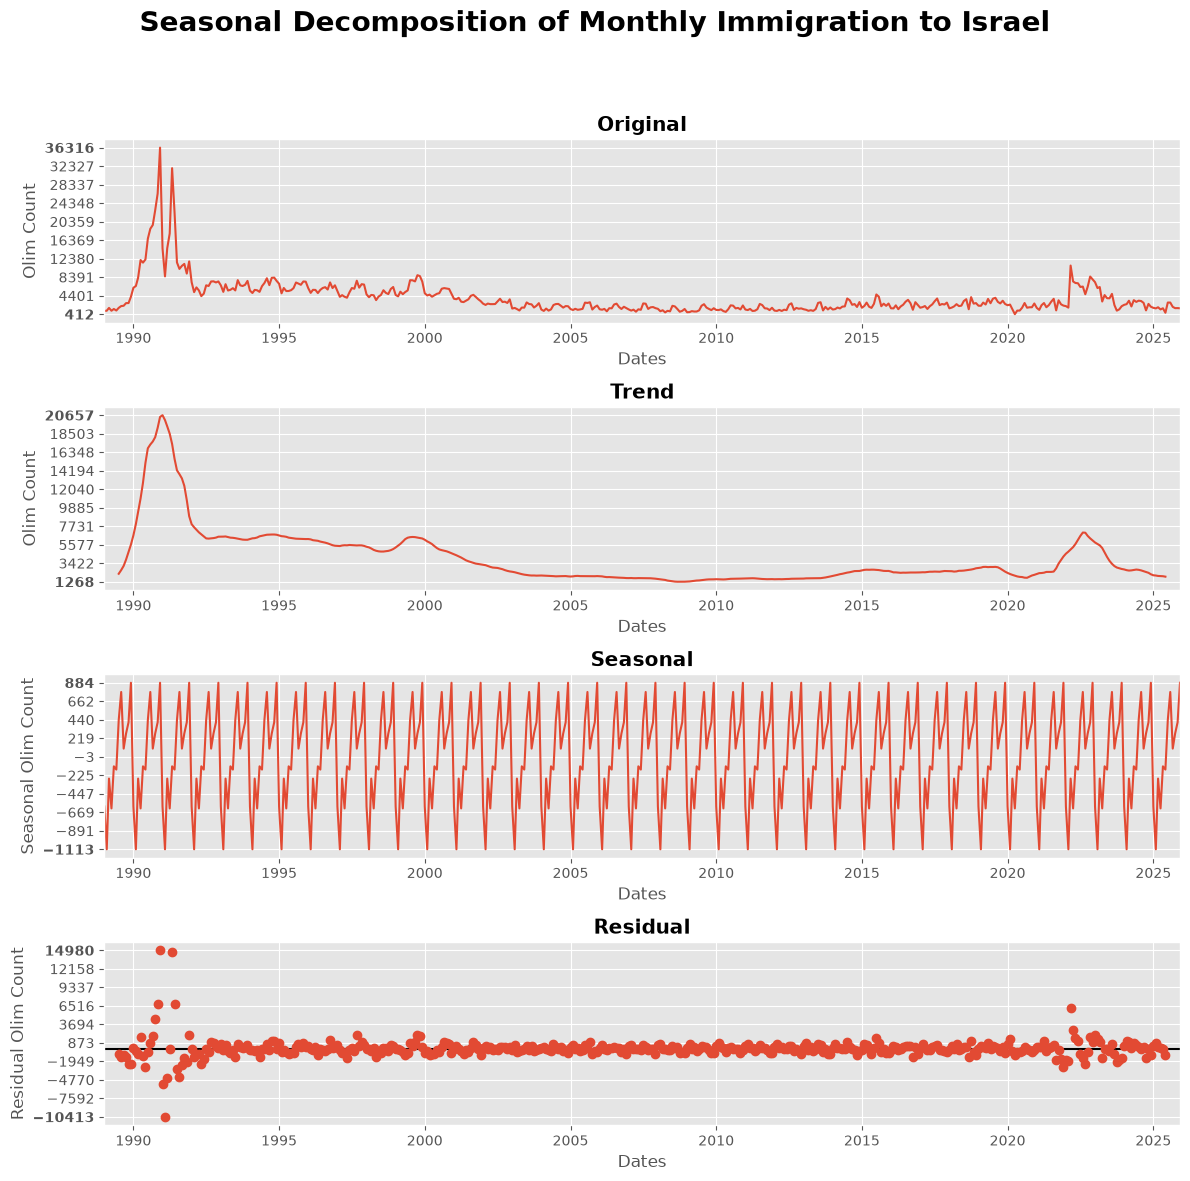

In [9]:
monthly = 12
model = "additive"
result = seasonal_decompose(
    final_df["Olim Count"], model=model, period=monthly
)

fig = result.plot()
fig.set_size_inches(12, 12)
fig.suptitle(
    "Seasonal Decomposition of Monthly Immigration to Israel",
    fontsize=20, fontweight="bold", y=0.98
)

components = [result.observed, result.trend, result.seasonal, result.resid]
labels = ["Original", "Trend", "Seasonal", "Residual"]
y_labels = ["Olim Count", "Olim Count", "Seasonal Olim Count", "Residual Olim Count"]
x_label = "Dates"
year_intervals = 5
y_ticks = 10

for ax, title, data, y_label in zip(fig.axes, labels, components, y_labels):
    # Titles and axis labels
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)

    # x-axis
    ax.xaxis.set_major_locator(mdates.YearLocator(year_intervals))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True)

    # y-axis
    ymin, ymax = data.min(), data.max()
    padding = (ymax - ymin) * 0.05 or 1
    ax.set_ylim(ymin - padding, ymax + padding)
    ax.set_yticks(np.linspace(ymin, ymax, y_ticks)) # Show y_ticks in y-axis, emphasizing min, max
    for tick in [ax.get_yticklabels()[0], ax.get_yticklabels()[-1]]: # ymin and ymax emphasized
        tick.set_fontweight("bold")


fig.tight_layout(rect=[0, 0, 1, 0.94])



An additive seasonal decomposition with a period of 12 months was applied to the monthly immigration series in order to examine its trend, seasonal patterns, and residual variation.

The trend component highlights significant changes in immigration levels over time, particularly during the early 1990s and around 2022. 
The seasonal component reveals recurring within-year fluctuations, while the residual component contains several pronounced outliers, suggesting that exceptional events also influence immigration patterns.